# 07. Кукуруза Dryad: прогноз по годам и условиям

Мульти-поколенческий набор CIMMYT с Dryad (генотипирование + полевые
испытания 2017–2020). Тут есть и
несколько лет, и два водных режима.

Что в данных:

- 3528 линий, 4612 маркеров (0/1, авторы уже отфильтровали по MAF ≥ 0.05);
- 4 года: 2017–2020, причём линии между годами **не пересекаются** —
  каждый год новое поколение;
- каждая линия измерена в двух режимах: оптимальный полив (Optimal) и
  контролируемая засуха (Drought);
- признаки: урожайность (GY), высота (PH), дата цветения (AD). Основной —
  GY.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# проект импортируется и из корня, и из папки notebooks/
for cand in [Path.cwd(), Path.cwd().parent]:
    if (cand / "gp_models" / "__init__.py").exists():
        sys.path.insert(0, str(cand))
        PROJECT = cand
        break

from gp_models import data, preprocessing as pp, gblup, rrblup, cv

matplotlib.rcParams["font.family"] = ["Liberation Sans", "Arimo", "DejaVu Sans"]
matplotlib.rcParams["svg.fonttype"] = "none"
FIGDIR = PROJECT / "figures"
FIGDIR.mkdir(exist_ok=True)
%matplotlib inline

Matplotlib is building the font cache; this may take a moment.


## Данные

Смотрю, что вообще внутри: сколько линий в каждом году и как ведут себя
признаки в двух режимах.

In [2]:
m = data.load_dryad_maize()
ph, X = m["pheno"], m["X"]
print("линий:", X.shape[0], "| маркеров:", X.shape[1])
print("\nлиний по годам:")
print(ph.groupby("Year").size().to_string())
print("\nсредние по годам и режимам (GY — урожайность, т/га):")
print(ph.groupby("Year")[["GY_Optimal", "GY_Drought"]].agg(["mean", "std"]).round(2).to_string())
print("\nNaN по колонкам:", ph.isna().sum().sum())

линий: 3528 | маркеров: 4612

линий по годам:
Year
2017     901
2018    1419
2019     722
2020     486

средние по годам и режимам (GY — урожайность, т/га):
     GY_Optimal       GY_Drought      
           mean   std       mean   std
Year                                  
2017       6.02  0.84       3.21  0.82
2018       8.04  1.27       3.11  0.77
2019       6.37  1.01       2.32  0.96
2020       7.58  1.68       2.26  0.92

NaN по колонкам: 9


findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font f

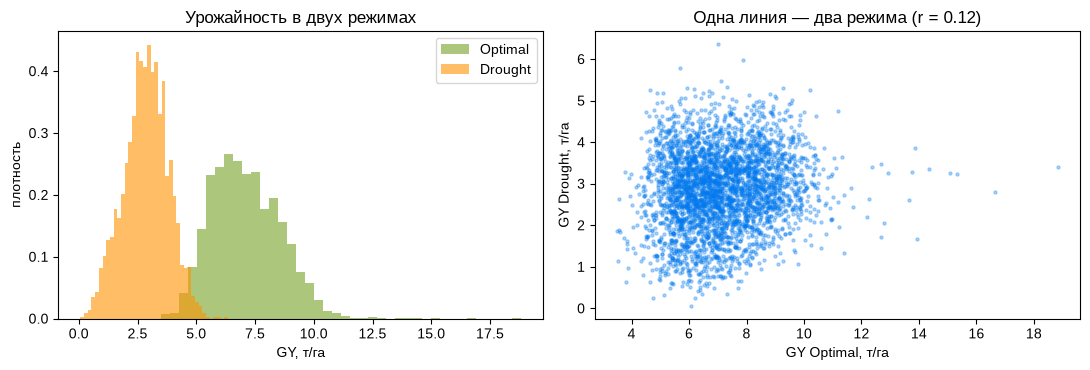

max GY_Optimal = 18.836  z-score = 7.9  — одна точка на 3528


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

ax = axes[0]
ax.hist(ph["GY_Optimal"].dropna(), bins=40, alpha=0.6, density=True,
        color="#75A025", label="Optimal")
ax.hist(ph["GY_Drought"].dropna(), bins=40, alpha=0.6, density=True,
        color="#FF9400", label="Drought")
ax.set_xlabel("GY, т/га"); ax.set_ylabel("плотность"); ax.legend()
ax.set_title("Урожайность в двух режимах")

ax = axes[1]
ok = ph[["GY_Optimal", "GY_Drought"]].dropna()
ax.scatter(ok["GY_Optimal"], ok["GY_Drought"], s=5, alpha=0.3, color="#0279EE")
r_od = np.corrcoef(ok["GY_Optimal"], ok["GY_Drought"])[0, 1]
ax.set_xlabel("GY Optimal, т/га"); ax.set_ylabel("GY Drought, т/га")
ax.set_title(f"Одна линия — два режима (r = {r_od:.2f})")
plt.tight_layout()
plt.savefig(FIGDIR / "dryad_data.png", dpi=150)
plt.savefig(FIGDIR / "dryad_data.svg")
plt.show()

# выброс справа на гистограмме — проверю, что это за точка
z = (ph["GY_Optimal"] - ph["GY_Optimal"].mean()) / ph["GY_Optimal"].std()
print("max GY_Optimal =", ph["GY_Optimal"].max(), " z-score =", round(z.max(), 1),
      " — одна точка на 3528")

## Подготовка: центрирование, матрица родства, наследуемость

Центрирование маркеров, G ВанРадена и по
REML оценка h² отдельно для каждой комбинации год × режим.

2017 Optimal : h2 = 0.668  (s2g=0.57, s2e=0.29, n=901)
2017 Drought : h2 = 0.704  (s2g=0.67, s2e=0.28, n=901)


2018 Optimal : h2 = 0.760  (s2g=1.67, s2e=0.53, n=1418)


2018 Drought : h2 = 0.576  (s2g=0.52, s2e=0.38, n=1418)
2019 Optimal : h2 = 0.700  (s2g=1.12, s2e=0.48, n=722)
2019 Drought : h2 = 0.808  (s2g=1.05, s2e=0.25, n=721)
2020 Optimal : h2 = 0.813  (s2g=3.70, s2e=0.85, n=486)
2020 Drought : h2 = 0.702  (s2g=0.65, s2e=0.28, n=486)


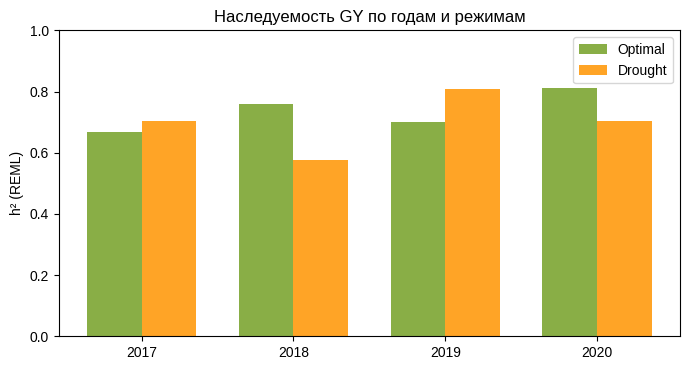

In [4]:
Z, p, c = pp.center_markers(X)
G = Z @ Z.T / c
years = sorted(ph["Year"].unique())
conds = ["Optimal", "Drought"]

h2tab = {}
for yv in years:
    idx = np.where(ph["Year"].to_numpy() == yv)[0]
    for cond in conds:
        y = ph[f"GY_{cond}"].to_numpy()[idx]
        ok = ~np.isnan(y)
        vc = pp.reml_variance_components(y[ok], G[np.ix_(idx[ok], idx[ok])])
        h2tab[(yv, cond)] = vc["h2"]
        print(f"{yv} {cond:8s}: h2 = {vc['h2']:.3f}  (s2g={vc['sigma2_g']:.2f}, s2e={vc['sigma2_e']:.2f}, n={ok.sum()})")

fig, ax = plt.subplots(figsize=(7, 3.8))
xpos = np.arange(len(years))
for k, cond in enumerate(conds):
    vals = [h2tab[(yv, cond)] for yv in years]
    ax.bar(xpos + (k - 0.5) * 0.36, vals, 0.36,
           color="#75A025" if cond == "Optimal" else "#FF9400", alpha=0.85, label=cond)
ax.set_xticks(xpos, years); ax.set_ylabel("h² (REML)"); ax.set_ylim(0, 1)
ax.legend(); ax.set_title("Наследуемость GY по годам и режимам")
plt.tight_layout()
plt.savefig(FIGDIR / "dryad_h2.png", dpi=150)
plt.savefig(FIGDIR / "dryad_h2.svg")
plt.show()

## Эксперимент A. Прогноз внутри года × режима

Случайные 70/30-разбиения, 20 повторов, λ из REML по train в каждом
повторе.

Метрики:

- **r** — корреляция прогноза с фактом на тесте;
- **RMSE** — ошибка в единицах признака (т/га);
- **топ-20%** — доля совпадения лучших 20% линий по прогнозу.


In [5]:
def gblup_train_test(ytr, Xtr, Xte):
    # всё по train: центрирование, нормировка c, REML — тест только предсказываем
    mean_tr = Xtr.mean(axis=0)
    Ztr, Zte = Xtr - mean_tr, Xte - mean_tr
    c_tr = 2.0 * np.sum(mean_tr * (1.0 - mean_tr))   # маркеры 0/1, p = mean
    Ktr = Ztr @ Ztr.T / c_tr
    Kte = Zte @ Ztr.T / c_tr
    vc = pp.reml_variance_components(ytr, Ktr)
    pred, _ = gblup.gblup_fit_predict(ytr, Ktr, Kte, vc["sigma2_g"], vc["sigma2_e"])
    return pred

resA = {}
for yv in years:
    idx = np.where(ph["Year"].to_numpy() == yv)[0]
    for cond in conds:
        y_all = ph[f"GY_{cond}"].to_numpy()[idx]
        ok = ~np.isnan(y_all)
        idx, y_all = idx[ok], y_all[ok]
        rs, rmses, tops = [], [], []
        for tr, te in cv.random_splits(len(idx), 0.7, n_reps=20, seed=1):
            pred = gblup_train_test(y_all[tr], X[idx[tr]], X[idx[te]])
            r, rmse = cv.metrics(y_all[te], pred)
            rs.append(r); rmses.append(rmse)
            tops.append(cv.topk_overlap(y_all[te], pred))
        resA[(yv, cond)] = dict(r=np.array(rs), rmse=np.array(rmses), top=np.array(tops))
        print(f"{yv} {cond:8s}: r = {np.mean(rs):.3f} +- {np.std(rs):.3f} | "
              f"RMSE = {np.mean(rmses):.2f} | топ-20% = {np.mean(tops):.2f}")

2017 Optimal : r = 0.671 +- 0.037 | RMSE = 0.64 | топ-20% = 0.57


2017 Drought : r = 0.635 +- 0.022 | RMSE = 0.64 | топ-20% = 0.55


2018 Optimal : r = 0.726 +- 0.019 | RMSE = 0.89 | топ-20% = 0.52


2018 Drought : r = 0.434 +- 0.022 | RMSE = 0.69 | топ-20% = 0.42


2019 Optimal : r = 0.587 +- 0.030 | RMSE = 0.82 | топ-20% = 0.47


2019 Drought : r = 0.752 +- 0.020 | RMSE = 0.64 | топ-20% = 0.59


2020 Optimal : r = 0.666 +- 0.065 | RMSE = 1.26 | топ-20% = 0.52


2020 Drought : r = 0.743 +- 0.030 | RMSE = 0.62 | топ-20% = 0.46


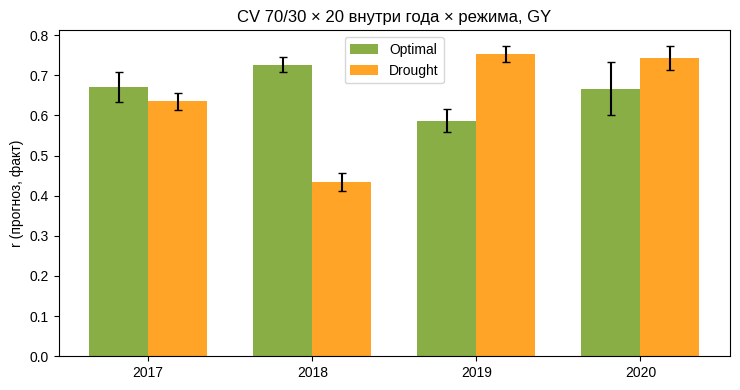

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4))
xpos = np.arange(len(years))
for k, cond in enumerate(conds):
    vals = [resA[(yv, cond)]["r"].mean() for yv in years]
    sds = [resA[(yv, cond)]["r"].std() for yv in years]
    ax.bar(xpos + (k - 0.5) * 0.36, vals, 0.36, yerr=sds, capsize=3,
           color="#75A025" if cond == "Optimal" else "#FF9400", alpha=0.85, label=cond)
ax.set_xticks(xpos, years); ax.set_ylabel("r (прогноз, факт)")
ax.set_title("CV 70/30 × 20 внутри года × режима, GY")
ax.legend()
plt.tight_layout()
plt.savefig(FIGDIR / "dryad_within.png", dpi=150)
plt.savefig(FIGDIR / "dryad_within.svg")
plt.show()



Точность внутри года — от 0.43 до 0.75 в зависимости от года и режима.

в 2018 засуха
сильно хуже (0.43 против 0.73), а в 2019 и 2020 — наоборот, лучше
оптимального режима (0.75 и 0.74). REML h² показывает то же.

## Эксперимент B. Перенос между режимами (внутри года)

У каждой линии есть измерения в обоих режимах. Схема: обучене модели на
фенотипах **Optimal** одних линий и предсказание **Drought** других
(тестовых) линий того же года. И наоборот.


In [7]:
resB = {}
for yv in years:
    idx = np.where(ph["Year"].to_numpy() == yv)[0]
    yO = ph["GY_Optimal"].to_numpy()[idx]
    yD = ph["GY_Drought"].to_numpy()[idx]
    ok = ~np.isnan(yO) & ~np.isnan(yD)
    idx, yO, yD = idx[ok], yO[ok], yD[ok]
    for tr_cond, te_cond, ytr_all, yte_all in [("Optimal", "Drought", yO, yD),
                                               ("Drought", "Optimal", yD, yO)]:
        rs, tops = [], []
        for tr, te in cv.random_splits(len(idx), 0.7, n_reps=20, seed=1):
            pred = gblup_train_test(ytr_all[tr], X[idx[tr]], X[idx[te]])
            r, _ = cv.metrics(yte_all[te], pred)
            rs.append(r); tops.append(cv.topk_overlap(yte_all[te], pred))
        resB[(yv, tr_cond, te_cond)] = dict(r=np.array(rs), top=np.array(tops))
        print(f"{yv} {tr_cond} -> {te_cond}: r = {np.mean(rs):.3f} +- {np.std(rs):.3f} | "
              f"топ-20% = {np.mean(tops):.2f}")

2017 Optimal -> Drought: r = 0.063 +- 0.047 | топ-20% = 0.19


2017 Drought -> Optimal: r = 0.022 +- 0.053 | топ-20% = 0.17


2018 Optimal -> Drought: r = -0.058 +- 0.058 | топ-20% = 0.12


2018 Drought -> Optimal: r = -0.103 +- 0.043 | топ-20% = 0.13


2019 Optimal -> Drought: r = 0.196 +- 0.059 | топ-20% = 0.37


2019 Drought -> Optimal: r = 0.153 +- 0.045 | топ-20% = 0.35


2020 Optimal -> Drought: r = 0.300 +- 0.073 | топ-20% = 0.37


2020 Drought -> Optimal: r = 0.271 +- 0.055 | топ-20% = 0.31


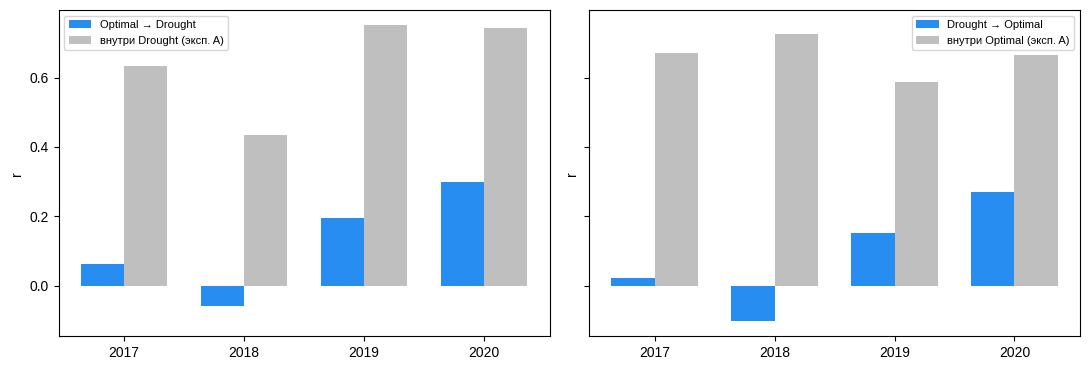

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (tr_cond, te_cond) in zip(axes, [("Optimal", "Drought"), ("Drought", "Optimal")]):
    vals = [resB[(yv, tr_cond, te_cond)]["r"].mean() for yv in years]
    ref = [resA[(yv, te_cond)]["r"].mean() for yv in years]
    xpos = np.arange(len(years))
    ax.bar(xpos - 0.18, vals, 0.36, color="#0279EE", alpha=0.85, label=f"{tr_cond} → {te_cond}")
    ax.bar(xpos + 0.18, ref, 0.36, color="grey", alpha=0.5, label=f"внутри {te_cond} (эксп. A)")
    ax.set_xticks(xpos, years); ax.set_ylabel("r"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGDIR / "dryad_across_cond.png", dpi=150)
plt.savefig(FIGDIR / "dryad_across_cond.svg")
plt.show()



Перенос между режимами слабый: в 2017 и 2018 — около нуля (местами
отрицательный), в 2019–2020 — 0.15–0.30. Для сравнения: внутри своего
режима в тех же годах 0.43–0.75.

генетика урожайности на поливе и в засухе
— во многом разная. Согласуется с фенотипной корреляцией
режимов по линиям — она всего 0.12. Практический вывод: модель для
засухи надо учить на засушливых данных, перенос с полива почти не
работает.

## Эксперимент C. Перенос между годами

Обучение на одном годе, предсказание на другом. Линии
между годами не пересекаются, так что это прогноз нового поколения —
связь только через родство (общие предки в селекционной программе).

Считаю все 12 пар (год train → год test) для GY в режиме Optimal
и рисую тепловую карту. Диагональ — среднее из эксперимента A (внутри
года) для сравнения. 

2017 -> 2018: r = 0.321 | топ-20% = 0.37


2017 -> 2019: r = 0.201 | топ-20% = 0.34


2017 -> 2020: r = 0.027 | топ-20% = 0.27


2018 -> 2017: r = 0.456 | топ-20% = 0.43


2018 -> 2019: r = 0.240 | топ-20% = 0.26


...

2019 -> 2018: r = 0.265 | топ-20% = 0.26


2019 -> 2020: r = 0.174 | топ-20% = 0.33


2020 -> 2017: r = 0.063 | топ-20% = 0.14


2020 -> 2018: r = 0.215 | топ-20% = 0.30


2020 -> 2019: r = 0.201 | топ-20% = 0.35


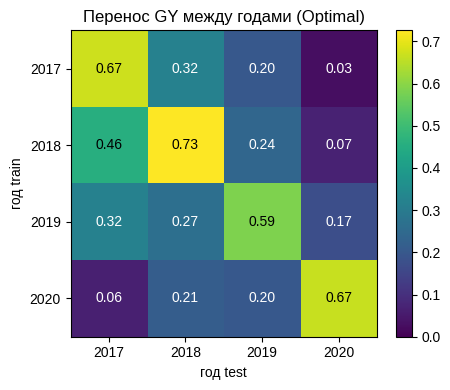

In [9]:
def year_data(yv, trait="GY", cond="Optimal"):
    idx = np.where(ph["Year"].to_numpy() == yv)[0]
    y = ph[f"{trait}_{cond}"].to_numpy()[idx]
    ok = ~np.isnan(y)
    return y[ok], X[idx[ok]]

R = np.full((4, 4), np.nan)
for i, ytr in enumerate(years):
    for j, yte in enumerate(years):
        if i == j:
            R[i, j] = resA[(ytr, "Optimal")]["r"].mean()
            continue
        y_tr, X_tr = year_data(ytr)
        y_te, X_te = year_data(yte)
        pred = gblup_train_test(y_tr, X_tr, X_te)
        r, _ = cv.metrics(y_te, pred)
        R[i, j] = r
        print(f"{ytr} -> {yte}: r = {r:.3f} | топ-20% = {cv.topk_overlap(y_te, pred):.2f}")

fig, ax = plt.subplots(figsize=(4.8, 4))
im = ax.imshow(R, vmin=0, vmax=max(0.6, np.nanmax(R)), cmap="viridis")
ax.set_xticks(range(4), years); ax.set_yticks(range(4), years)
ax.set_xlabel("год test"); ax.set_ylabel("год train")
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{R[i, j]:.2f}", ha="center", va="center",
                color="white" if R[i, j] < 0.35 else "black", fontsize=10)
ax.set_title("Перенос GY между годами (Optimal)")
fig.colorbar(im, fraction=0.046)
plt.tight_layout()
plt.savefig(FIGDIR / "dryad_years_heatmap.png", dpi=150)
plt.savefig(FIGDIR / "dryad_years_heatmap.svg")
plt.show()



Все 12 внедиагональных r положительные (0.03–0.46) — перенос между
поколениями есть. Но он заметно ниже диагонали и сильно асимметричный:

- лучше всего предсказывается 2017 год (0.32–0.46), хуже всего — 2020
  (0.03–0.17);
- размер train решает: 2018 (1419 линий);
- ближние годы в среднем точнее дальних (2017→2018: 0.32, а 2017→2020:
  0.03).


## Эксперимент D. Leave-one-year-out: учу на трёх годах, предсказываю четвёртый



train 3 года -> 2017 (Optimal ): r = 0.378 | топ-20% = 0.39


train 3 года -> 2018 (Optimal ): r = 0.340 | топ-20% = 0.38


train 3 года -> 2019 (Optimal ): r = 0.335 | топ-20% = 0.38


train 3 года -> 2020 (Optimal ): r = 0.108 | топ-20% = 0.29


train 3 года -> 2017 (Drought ): r = 0.135 | топ-20% = 0.32


train 3 года -> 2018 (Drought ): r = 0.226 | топ-20% = 0.27


train 3 года -> 2019 (Drought ): r = 0.184 | топ-20% = 0.31


train 3 года -> 2020 (Drought ): r = -0.071 | топ-20% = 0.16


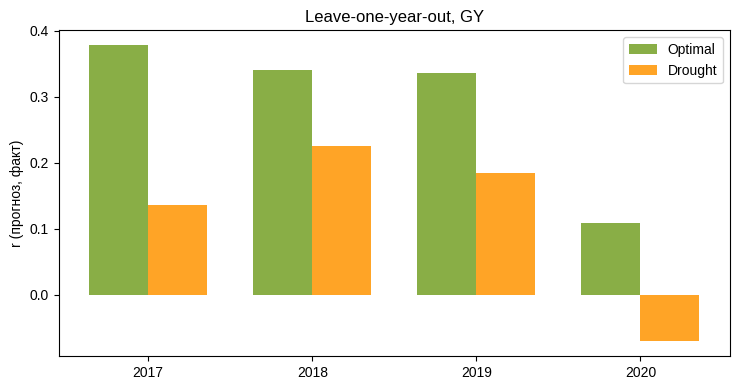

In [10]:
resD = {}
for cond in conds:
    for yte in years:
        y_tr_all, X_tr_all = [], []
        for yv in years:
            if yv == yte:
                continue
            y_tr, X_tr = year_data(yv, "GY", cond)
            y_tr_all.append((y_tr - y_tr.mean()) / y_tr.std())   # стандартизация внутри года
            X_tr_all.append(X_tr)
        y_tr = np.concatenate(y_tr_all)
        X_tr = np.vstack(X_tr_all)
        y_te, X_te = year_data(yte, "GY", cond)
        pred = gblup_train_test(y_tr, X_tr, X_te)
        r, _ = cv.metrics(y_te, pred)
        resD[(cond, yte)] = r
        print(f"train 3 года -> {yte} ({cond:8s}): r = {r:.3f} | топ-20% = {cv.topk_overlap(y_te, pred):.2f}")

fig, ax = plt.subplots(figsize=(7.5, 4))
xpos = np.arange(len(years))
for k, cond in enumerate(conds):
    vals = [resD[(cond, yv)] for yv in years]
    ax.bar(xpos + (k - 0.5) * 0.36, vals, 0.36,
           color="#75A025" if cond == "Optimal" else "#FF9400", alpha=0.85, label=cond)
ax.set_xticks(xpos, years); ax.set_ylabel("r (прогноз, факт)")
ax.set_title("Leave-one-year-out, GY")
ax.legend()
plt.tight_layout()
plt.savefig(FIGDIR / "dryad_loyo.png", dpi=150)
plt.savefig(FIGDIR / "dryad_loyo.svg")
plt.show()



Объединение трёх лет помогает для 2017–2019 в оптимальном режиме
(r = 0.34–0.38 — выше, чем у большинства одиночных пар в эксперименте C).
Для 2020 и для засухи — слабо (0.11 и ниже; для 2020 Drought
около нуля). 

# BayesA на переносе между годами

Сравниваю с RR-BLUP на тех же данных. 

In [ ]:
from gp_models import brr, bayesa
import time

y_tr, X_tr = [], []
for yv in [2017, 2018, 2019]:
    yy, XX = year_data(yv, "GY", "Optimal")
    y_tr.append((yy - yy.mean()) / yy.std()); X_tr.append(XX)
y_tr = np.concatenate(y_tr); X_tr = np.vstack(X_tr)
y_te, X_te = year_data(2020, "GY", "Optimal")

# RR-BLUP на тех же данных
mean_tr = X_tr.mean(axis=0)
Ztr, Zte = X_tr - mean_tr, X_te - mean_tr
c_tr = 2.0 * np.sum(mean_tr * (1.0 - mean_tr))
Ktr = Ztr @ Ztr.T / c_tr
vc = pp.reml_variance_components(y_tr, Ktr)
lam = vc["sigma2_e"] / (vc["sigma2_g"] / c_tr)
fit_rr = rrblup.rrblup_fit(y_tr, Ztr, lam)
pred_rr = fit_rr["mu"] + Zte @ fit_rr["beta"]
print(f"RR-BLUP: r = {cv.metrics(y_te, pred_rr)[0]:.3f}")

t0 = time.time()
fa = bayesa.bayesa_fit(y_tr, X_tr, n_iter=12000, burn_in=2000, thin=5, seed=7)
pred_ba = fa["mu"] + Zte @ fa["beta"]
print(f"BayesA:  r = {cv.metrics(y_te, pred_ba)[0]:.3f}  ({(time.time()-t0)/60:.1f} мин)")
print(f"corr(beta_BayesA, beta_RRBLUP) = {np.corrcoef(fa['beta'], fit_rr['beta'])[0,1]:.4f}")

RR-BLUP: r = 0.108


BayesA:  r = 0.087  (1.6 мин)
corr(beta_BayesA, beta_RRBLUP) = 0.9692




BayesA и RR-BLUP снова почти совпали: корреляция эффектов 0.97, r на
тесте 0.09 против 0.11. На полигенной урожайности тяжелохвостый приор
ничего не даёт.

## Контраст: высота растения (PH)

Высота обычно наследуется заметно лучше урожайности (меньше шума).

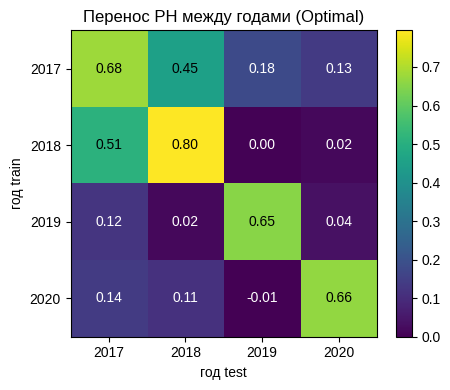

            test 2017  test 2018  test 2019  test 2020
train 2017       0.68       0.45       0.18       0.13
train 2018       0.51       0.80       0.00       0.02
train 2019       0.12       0.02       0.65       0.04
train 2020       0.14       0.11      -0.01       0.66


In [12]:
R_ph = np.full((4, 4), np.nan)
for i, ytr in enumerate(years):
    for j, yte in enumerate(years):
        y_tr, X_tr = year_data(ytr, "PH", "Optimal")
        y_te, X_te = year_data(yte, "PH", "Optimal")
        if i == j:
            rs = []
            for tr, te in cv.random_splits(len(y_tr), 0.7, n_reps=10, seed=1):
                pred = gblup_train_test(y_tr[tr], X_tr[tr], X_tr[te])
                rs.append(cv.metrics(y_tr[te], pred)[0])
            R_ph[i, j] = np.mean(rs)
        else:
            pred = gblup_train_test(y_tr, X_tr, X_te)
            R_ph[i, j] = cv.metrics(y_te, pred)[0]

fig, ax = plt.subplots(figsize=(4.8, 4))
im = ax.imshow(R_ph, vmin=0, vmax=max(0.6, np.nanmax(R_ph)), cmap="viridis")
ax.set_xticks(range(4), years); ax.set_yticks(range(4), years)
ax.set_xlabel("год test"); ax.set_ylabel("год train")
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{R_ph[i, j]:.2f}", ha="center", va="center",
                color="white" if R_ph[i, j] < 0.35 else "black", fontsize=10)
ax.set_title("Перенос PH между годами (Optimal)")
fig.colorbar(im, fraction=0.046)
plt.tight_layout()
plt.savefig(FIGDIR / "dryad_ph_heatmap.png", dpi=150)
plt.savefig(FIGDIR / "dryad_ph_heatmap.svg")
plt.show()
print(pd.DataFrame(R_ph, index=[f'train {y}' for y in years],
                     columns=[f'test {y}' for y in years]).round(2))




внутри года высота предсказывается лучше урожайности
(0.66–0.80 по диагонали). А вот перенос между годами у PH даже слабее,
чем у GY (в среднем ~0.11): высокая наследуемость сама по себе не
гарантирует переносимость между поколениями. Пара 2017→2018 (0.45)
показывает, что при близком родстве перенос возможен и для высоты.

## Выводы

1. **Внутри года всё работает неплохо**: r = 0.43–0.75 для урожайности
   (и 0.66–0.80 для высоты). Для селекции внутри одного поколения модель справляется.
2. **Между режимами перенос слабый** (0–0.3): G×E сильное, генетика
   урожайности на поливе и в засухе во многом разная. Модель под засуху
   надо учить на засухе.
3. **Между годами перенос есть, но так сее** (0.03–0.46, в среднем
   ~0.2): поколения связаны родством, но дальние
   годы предсказываются хуже ближних. Лучше всех предсказывается 2017,
   хуже всех — 2020.
4. **Объединение лет помогает**, когда тестовый год
   похож на обучающие: для 2017–2019 r = 0.34–0.38.
5. **BayesA ≈ RR-BLUP** урожайность полигенна, тяжёлые хвосты
   не нужны.




In [14]:
rows = []
for (yv, cond), r in resA.items():
    rows.append(("A_внутри", f"{yv} {cond}", f"{yv} {cond}",
                 r["r"].mean(), r["rmse"].mean(), r["top"].mean()))
for (yv, trc, tec), r in resB.items():
    rows.append(("B_между_режимами", f"{yv} {trc}", f"{yv} {tec}",
                 r["r"].mean(), np.nan, r["top"].mean()))
for i, ytr in enumerate(years):
    for j, yte in enumerate(years):
        if i != j:
            rows.append(("C_между_годами", f"{ytr} Optimal", f"{yte} Optimal",
                         R[i, j], np.nan, np.nan))
for (cond, yte), r in resD.items():
    rows.append(("D_loyo", f"3 года {cond}", f"{yte} {cond}", r, np.nan, np.nan))
tab = pd.DataFrame(rows, columns=["experiment", "train", "test", "r", "rmse", "top20"])
(PROJECT / "results").mkdir(exist_ok=True)
tab.to_csv(PROJECT / "results" / "dryad_summary.csv", index=False)
print(tab.round(3).to_string(index=False))

      experiment          train         test      r  rmse  top20
        A_внутри   2017 Optimal 2017 Optimal  0.671 0.635  0.575
        A_внутри   2017 Drought 2017 Drought  0.635 0.642  0.549
        A_внутри   2018 Optimal 2018 Optimal  0.726 0.894  0.519
        A_внутри   2018 Drought 2018 Drought  0.434 0.690  0.416
        A_внутри   2019 Optimal 2019 Optimal  0.587 0.818  0.473
        A_внутри   2019 Drought 2019 Drought  0.752 0.637  0.588
        A_внутри   2020 Optimal 2020 Optimal  0.666 1.261  0.522
        A_внутри   2020 Drought 2020 Drought  0.743 0.617  0.455
B_между_режимами   2017 Optimal 2017 Drought  0.063   NaN  0.188
B_между_режимами   2017 Drought 2017 Optimal  0.022   NaN  0.169
B_между_режимами   2018 Optimal 2018 Drought -0.058   NaN  0.124
B_между_режимами   2018 Drought 2018 Optimal -0.103   NaN  0.129
B_между_режимами   2019 Optimal 2019 Drought  0.196   NaN  0.370
B_между_режимами   2019 Drought 2019 Optimal  0.153   NaN  0.347
B_между_режимами   2020 O